# ML-10 — Content Action Playbook

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/piasa19/flyrank-ml-internship-starter/blob/main/work/notebooks/w07_action_playbook.ipynb)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Ranked actions + reason codes

*The queue: what to do first, and why, in words a human trusts.*

In [12]:
import os
import glob

print("Current folder:", os.getcwd())
print("\nFiles in current folder:")
print(os.listdir())

print("\nCSV files found:")
print(glob.glob("**/*.csv", recursive=True))

Current folder: /content

Files in current folder:
['.config', 'sample_data']

CSV files found:
['sample_data/california_housing_train.csv', 'sample_data/mnist_test.csv', 'sample_data/california_housing_test.csv', 'sample_data/mnist_train_small.csv']


In [13]:
import os

print(os.listdir("/content"))

['.config', 'sample_data']


In [14]:
from google.colab import files
uploaded = files.upload()

Saving content_refresh_anonymized (1).csv to content_refresh_anonymized (1).csv


In [15]:
import pandas as pd

DATA_PATH = "/content/content_refresh_anonymized (1).csv"

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())

Dataset loaded successfully!
Shape: (30000, 44)

First 5 rows:


,content_id,client_id,search_volume,competition,competition_level,cpc,content_type,main_intent,word_count,char_count,...,char_count_tier,ctr,avg_position,engagement_rate,scroll_rate,ai_traffic_pct,impression_tier,position_tier,trend_direction,trend_pct
0,content_304f48230142,client_f369cb89fc,10.0,0.67,HIGH,2.05,keyword article,transactional,3221.0,20457.0,...,15000-25000,0.76,10.6,5.88,4.55,0.0,good,striking,down,-41.4
1,content_a1fb4e703a9e,client_4e07408562,90.0,0.01,LOW,0.05,keyword article,informational,2481.0,15562.0,...,15000-25000,0.05,20.3,0.00,10.00,0.0,good,page_3_5,down,-57.7
2,content_9aa793d4d895,client_7f2253d7e2,0.0,0.00,LOW,0.00,keyword article,informational,3515.0,23643.0,...,15000-25000,0.09,36.5,0.00,28.57,0.0,good,page_3_5,down,-60.9
3,content_331d6c4de07b,client_19581e27de,10.0,0.00,LOW,0.00,keyword article,commercial,NaN,NaN,...,NaN,0.49,6.2,1.28,3.45,0.0,good,page_1,stable,-13.8
4,content_d99b7a2d90ca,client_3fdba35f04,0.0,0.00,LOW,0.00,keyword article,informational,2803.0,17469.0,...,15000-25000,0.13,44.0,0.00,24.29,0.0,good,page_3_5,down,-34.7


In [16]:
print("Dataset columns:")
print(df.columns.tolist())

Dataset columns:
['content_id', 'client_id', 'search_volume', 'competition', 'competition_level', 'cpc', 'content_type', 'main_intent', 'word_count', 'char_count', 'provider_used', 'model_used', 'impressions_90d', 'clicks_90d', 'pageviews_90d', 'sessions_90d', 'users_90d', 'engaged_sessions_90d', 'ai_sessions_90d', 'scroll_events_90d', 'days_with_impressions', 'days_with_sessions', 'impressions_last_30d', 'clicks_last_30d', 'sessions_last_30d', 'impressions_prev_30d', 'clicks_prev_30d', 'sessions_prev_30d', 'content_age_days', 'age_tier', 'age_tier_order', 'days_since_last_update', 'freshness_tier', 'word_count_tier', 'char_count_tier', 'ctr', 'avg_position', 'engagement_rate', 'scroll_rate', 'ai_traffic_pct', 'impression_tier', 'position_tier', 'trend_direction', 'trend_pct']


In [17]:
# ============================================================
# ML-10 | Section 1: Ranked Actions + Reason Codes
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. Check Dataset
# ------------------------------------------------------------

print("Dataset shape:", df.shape)

required_columns = [
    "content_id",
    "search_volume",
    "clicks_last_30d",
    "clicks_prev_30d",
    "days_since_last_update",
    "freshness_tier",
    "ctr",
    "avg_position",
    "trend_direction"
]

missing_columns = [
    col for col in required_columns if col not in df.columns
]

if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}")

# Create a working copy
data = df.copy()

# Convert important columns into numeric format
numeric_columns = [
    "search_volume",
    "clicks_last_30d",
    "clicks_prev_30d",
    "days_since_last_update",
    "ctr",
    "avg_position"
]

for col in numeric_columns:
    data[col] = pd.to_numeric(data[col], errors="coerce")

# ------------------------------------------------------------
# 2. Create Reason Codes
# ------------------------------------------------------------

def get_reason_codes(row):

    reasons = []

    # Traffic decline
    if (
        pd.notna(row["clicks_last_30d"])
        and pd.notna(row["clicks_prev_30d"])
        and row["clicks_last_30d"] < row["clicks_prev_30d"]
    ):
        reasons.append("TRAFFIC_DECLINING")

    # Old content
    if (
        pd.notna(row["days_since_last_update"])
        and row["days_since_last_update"] >= 180
    ):
        reasons.append("CONTENT_STALE")

    # Low CTR
    if (
        pd.notna(row["ctr"])
        and row["ctr"] < data["ctr"].median()
    ):
        reasons.append("LOW_CTR")

    # Ranking opportunity
    if (
        pd.notna(row["avg_position"])
        and 4 <= row["avg_position"] <= 20
    ):
        reasons.append("RANKING_OPPORTUNITY")

    # Search demand
    if (
        pd.notna(row["search_volume"])
        and row["search_volume"] >= data["search_volume"].quantile(0.75)
    ):
        reasons.append("HIGH_SEARCH_DEMAND")

    if not reasons:
        reasons.append("NO_STRONG_SIGNAL")

    return reasons


data["reason_codes"] = data.apply(get_reason_codes, axis=1)

# ------------------------------------------------------------
# 3. Calculate Priority Score
# ------------------------------------------------------------

data["priority_score"] = 0

# Traffic decline signal
data.loc[
    data.apply(
        lambda r: pd.notna(r["clicks_last_30d"])
        and pd.notna(r["clicks_prev_30d"])
        and r["clicks_last_30d"] < r["clicks_prev_30d"],
        axis=1
    ),
    "priority_score"
] += 30

# Stale content signal
data.loc[
    data["days_since_last_update"] >= 180,
    "priority_score"
] += 20

# Low CTR signal
data.loc[
    data["ctr"] < data["ctr"].median(),
    "priority_score"
] += 15

# Ranking opportunity signal
data.loc[
    data["avg_position"].between(4, 20),
    "priority_score"
] += 20

# High search demand signal
data.loc[
    data["search_volume"] >= data["search_volume"].quantile(0.75),
    "priority_score"
] += 15

# ------------------------------------------------------------
# 4. Suggest Actions
# ------------------------------------------------------------

def suggest_action(reasons):

    if "TRAFFIC_DECLINING" in reasons and "CONTENT_STALE" in reasons:
        return "Refresh content and investigate traffic decline"

    elif "LOW_CTR" in reasons:
        return "Review title and meta description"

    elif "RANKING_OPPORTUNITY" in reasons:
        return "Improve content relevance and on-page SEO"

    elif "CONTENT_STALE" in reasons:
        return "Review and update outdated content"

    elif "HIGH_SEARCH_DEMAND" in reasons:
        return "Review content for search demand opportunities"

    else:
        return "Monitor performance"


data["suggested_action"] = data["reason_codes"].apply(
    suggest_action
)

# ------------------------------------------------------------
# 5. Create Ranked Action Queue
# ------------------------------------------------------------

action_queue = data[
    [
        "content_id",
        "priority_score",
        "reason_codes",
        "suggested_action"
    ]
].copy()

# Convert reason codes into readable text
action_queue["reason_codes"] = action_queue["reason_codes"].apply(
    lambda x: ", ".join(x)
)

# Sort by priority score
action_queue = action_queue.sort_values(
    by="priority_score",
    ascending=False
).reset_index(drop=True)

# Add rank
action_queue.insert(
    0,
    "rank",
    range(1, len(action_queue) + 1)
)

# ------------------------------------------------------------
# 6. Display Top 20 Actions
# ------------------------------------------------------------

print("\nTOP 20 PRIORITY ACTIONS")
print("=" * 70)

display(action_queue.head(20))

# ------------------------------------------------------------
# 7. Save Action Queue
# ------------------------------------------------------------

OUTPUT_PATH = "/content/ranked_action_queue.csv"

action_queue.to_csv(
    OUTPUT_PATH,
    index=False
)

print("\nAction queue created successfully!")
print("Total content items:", len(action_queue))
print("Saved file:", OUTPUT_PATH)

# ------------------------------------------------------------
# 8. Priority Summary
# ------------------------------------------------------------

print("\nPRIORITY SUMMARY")
print("=" * 40)

print(
    action_queue["priority_score"]
    .value_counts()
    .sort_index(ascending=False)
)

print("\nReason Code Summary:")

reason_summary = (
    action_queue["reason_codes"]
    .str.split(", ")
    .explode()
    .value_counts()
)

display(reason_summary)

Dataset shape: (30000, 44)

TOP 20 PRIORITY ACTIONS


,rank,content_id,priority_score,reason_codes,suggested_action
0,1,content_18aca5eb5eef,80,"TRAFFIC_DECLINING, LOW_CTR, RANKING_OPPORTUNIT...",Review title and meta description
1,2,content_4e1fa0141e14,80,"TRAFFIC_DECLINING, LOW_CTR, RANKING_OPPORTUNIT...",Review title and meta description
2,3,content_8d5d91ac837d,80,"TRAFFIC_DECLINING, LOW_CTR, RANKING_OPPORTUNIT...",Review title and meta description
3,4,content_6a508b2eca69,80,"TRAFFIC_DECLINING, LOW_CTR, RANKING_OPPORTUNIT...",Review title and meta description
4,5,content_3c5020578d4f,80,"TRAFFIC_DECLINING, LOW_CTR, RANKING_OPPORTUNIT...",Review title and meta description
5,6,content_0021011e9850,80,"TRAFFIC_DECLINING, LOW_CTR, RANKING_OPPORTUNIT...",Review title and meta description
6,7,content_b115f7c74779,80,"TRAFFIC_DECLINING, LOW_CTR, RANKING_OPPORTUNIT...",Review title and meta description
7,8,content_7b6c63658332,80,"TRAFFIC_DECLINING, LOW_CTR, RANKING_OPPORTUNIT...",Review title and meta description
8,9,content_0bf366a6fdd6,80,"TRAFFIC_DECLINING, LOW_CTR, RANKING_OPPORTUNIT...",Review title and meta description
9,10,content_ec0e0f96eb11,80,"TRAFFIC_DECLINING, LOW_CTR, RANKING_OPPORTUNIT...",Review title and meta description



Action queue created successfully!
Total content items: 30000
Saved file: /content/ranked_action_queue.csv

PRIORITY SUMMARY
priority_score
80     111
70      12
65    1531
60      63
55      69
50    5243
45     652
40      30
35    7022
30    3645
20    4225
15    5426
0     1971
Name: count, dtype: int64

Reason Code Summary:


,count
reason_codes,
RANKING_OPPORTUNITY,18180
LOW_CTR,14810
HIGH_SEARCH_DEMAND,9140
TRAFFIC_DECLINING,6806
NO_STRONG_SIGNAL,1971
CONTENT_STALE,174


## 2. Intended use and limits

*Who uses this, for what — and where it stops being valid.*

In [18]:
# ============================================================
# ML-10 | Section 2: Intended Use and Limits
# ============================================================

import json
import os

# ------------------------------------------------------------
# 1. Intended Use
# ------------------------------------------------------------

intended_use = [
    "Identify content items that may need attention.",
    "Prioritize content based on traffic and performance signals.",
    "Find content with declining clicks.",
    "Identify content with comparatively low CTR.",
    "Highlight SEO ranking opportunities.",
    "Support human review and decision-making."
]

# ------------------------------------------------------------
# 2. Limitations
# ------------------------------------------------------------

limitations = [
    "The priority score is based on rule-based scoring.",
    "The score does not guarantee future content performance.",
    "Missing or incorrect data may affect the results.",
    "Thresholds and score weights are provisional.",
    "The system does not fully understand content quality or business context.",
    "Human review is required before taking action."
]

# ------------------------------------------------------------
# 3. No-Go List
# ------------------------------------------------------------

no_go_list = [
    "Do not automatically publish or modify content.",
    "Do not delete content based only on its priority score.",
    "Do not guarantee SEO ranking improvements.",
    "Do not make final business decisions without human approval."
]

# ------------------------------------------------------------
# 4. Display Results
# ------------------------------------------------------------

print("=" * 60)
print("SECTION 2: INTENDED USE AND LIMITS")
print("=" * 60)

print("\nINTENDED USE:")
for i, item in enumerate(intended_use, 1):
    print(f"{i}. {item}")

print("\nLIMITATIONS:")
for i, item in enumerate(limitations, 1):
    print(f"{i}. {item}")

print("\nNO-GO LIST:")
for i, item in enumerate(no_go_list, 1):
    print(f"{i}. {item}")

# ------------------------------------------------------------
# 5. Save Results as JSON
# ------------------------------------------------------------

section_2_output = {
    "intended_use": intended_use,
    "limitations": limitations,
    "no_go_list": no_go_list
}

OUTPUT_PATH = "/content/section_2_intended_use_limits.json"

with open(OUTPUT_PATH, "w") as file:
    json.dump(section_2_output, file, indent=4)

print("\nSection 2 completed successfully!")
print("Output saved to:", OUTPUT_PATH)

SECTION 2: INTENDED USE AND LIMITS

INTENDED USE:
1. Identify content items that may need attention.
2. Prioritize content based on traffic and performance signals.
3. Find content with declining clicks.
4. Identify content with comparatively low CTR.
5. Highlight SEO ranking opportunities.
6. Support human review and decision-making.

LIMITATIONS:
1. The priority score is based on rule-based scoring.
2. The score does not guarantee future content performance.
3. Missing or incorrect data may affect the results.
4. Thresholds and score weights are provisional.
5. The system does not fully understand content quality or business context.
6. Human review is required before taking action.

NO-GO LIST:
1. Do not automatically publish or modify content.
2. Do not delete content based only on its priority score.
3. Do not guarantee SEO ranking improvements.
4. Do not make final business decisions without human approval.

Section 2 completed successfully!
Output saved to: /content/section_2_in

## 3. Human review + the no-go list

*What a person must check before acting. What should never be automated.*

In [19]:
# ============================================================
# ML-10 | Section 3: Human Review + No-Go List
# ============================================================

import pandas as pd
import json

# ------------------------------------------------------------
# 1. Create Human Review Queue
# ------------------------------------------------------------

review_queue = action_queue.copy()

# Add human review columns
review_queue["review_status"] = "PENDING"
review_queue["reviewer_decision"] = "NOT_REVIEWED"
review_queue["reviewer_comments"] = ""

# ------------------------------------------------------------
# 2. Define Human Review Checklist
# ------------------------------------------------------------

review_checklist = [
    "Check whether the traffic decline is genuine.",
    "Verify whether the data is complete and accurate.",
    "Check whether the suggested action is relevant.",
    "Review the content quality and business context.",
    "Confirm that the proposed update is useful.",
    "Get human approval before implementing any action."
]

print("=" * 60)
print("SECTION 3: HUMAN REVIEW CHECKLIST")
print("=" * 60)

for i, item in enumerate(review_checklist, 1):
    print(f"{i}. {item}")

# ------------------------------------------------------------
# 3. Define Approval Rules
# ------------------------------------------------------------

def review_rule(row):

    if row["priority_score"] >= 65:
        return "HIGH_PRIORITY_REVIEW"

    elif row["priority_score"] >= 35:
        return "MEDIUM_PRIORITY_REVIEW"

    else:
        return "LOW_PRIORITY_REVIEW"


review_queue["review_category"] = review_queue.apply(
    review_rule,
    axis=1
)

# ------------------------------------------------------------
# 4. Define No-Go Rules
# ------------------------------------------------------------

no_go_rules = [
    "Never automatically publish content.",
    "Never delete content based only on priority score.",
    "Never make changes without human approval.",
    "Never treat the priority score as a guaranteed prediction.",
    "Never expose private client information."
]

print("\nNO-GO RULES")
print("=" * 60)

for i, rule in enumerate(no_go_rules, 1):
    print(f"{i}. {rule}")

# ------------------------------------------------------------
# 5. Display Review Queue
# ------------------------------------------------------------

print("\nHUMAN REVIEW QUEUE")
print("=" * 60)

display(review_queue.head(20))

# ------------------------------------------------------------
# 6. Review Category Summary
# ------------------------------------------------------------

print("\nREVIEW CATEGORY SUMMARY")
print("=" * 60)

display(
    review_queue["review_category"].value_counts()
)

# ------------------------------------------------------------
# 7. Save Human Review Data
# ------------------------------------------------------------

review_queue.to_csv(
    "/content/human_review_queue.csv",
    index=False
)

# ------------------------------------------------------------
# 8. Save Review Checklist and No-Go Rules
# ------------------------------------------------------------

section_3_output = {
    "review_checklist": review_checklist,
    "no_go_rules": no_go_rules,
    "approval_policy": (
        "All suggested actions require human review "
        "and approval before implementation."
    )
}

with open(
    "/content/section_3_human_review.json",
    "w"
) as file:
    json.dump(section_3_output, file, indent=4)

print("\nSection 3 completed successfully!")
print("Human review queue saved.")
print("Review checklist saved.")

SECTION 3: HUMAN REVIEW CHECKLIST
1. Check whether the traffic decline is genuine.
2. Verify whether the data is complete and accurate.
3. Check whether the suggested action is relevant.
4. Review the content quality and business context.
5. Confirm that the proposed update is useful.
6. Get human approval before implementing any action.

NO-GO RULES
1. Never automatically publish content.
2. Never delete content based only on priority score.
3. Never make changes without human approval.
4. Never treat the priority score as a guaranteed prediction.
5. Never expose private client information.

HUMAN REVIEW QUEUE


,rank,content_id,priority_score,reason_codes,suggested_action,review_status,reviewer_decision,reviewer_comments,review_category
0,1,content_18aca5eb5eef,80,"TRAFFIC_DECLINING, LOW_CTR, RANKING_OPPORTUNIT...",Review title and meta description,PENDING,NOT_REVIEWED,,HIGH_PRIORITY_REVIEW
1,2,content_4e1fa0141e14,80,"TRAFFIC_DECLINING, LOW_CTR, RANKING_OPPORTUNIT...",Review title and meta description,PENDING,NOT_REVIEWED,,HIGH_PRIORITY_REVIEW
2,3,content_8d5d91ac837d,80,"TRAFFIC_DECLINING, LOW_CTR, RANKING_OPPORTUNIT...",Review title and meta description,PENDING,NOT_REVIEWED,,HIGH_PRIORITY_REVIEW
3,4,content_6a508b2eca69,80,"TRAFFIC_DECLINING, LOW_CTR, RANKING_OPPORTUNIT...",Review title and meta description,PENDING,NOT_REVIEWED,,HIGH_PRIORITY_REVIEW
4,5,content_3c5020578d4f,80,"TRAFFIC_DECLINING, LOW_CTR, RANKING_OPPORTUNIT...",Review title and meta description,PENDING,NOT_REVIEWED,,HIGH_PRIORITY_REVIEW
5,6,content_0021011e9850,80,"TRAFFIC_DECLINING, LOW_CTR, RANKING_OPPORTUNIT...",Review title and meta description,PENDING,NOT_REVIEWED,,HIGH_PRIORITY_REVIEW
6,7,content_b115f7c74779,80,"TRAFFIC_DECLINING, LOW_CTR, RANKING_OPPORTUNIT...",Review title and meta description,PENDING,NOT_REVIEWED,,HIGH_PRIORITY_REVIEW
7,8,content_7b6c63658332,80,"TRAFFIC_DECLINING, LOW_CTR, RANKING_OPPORTUNIT...",Review title and meta description,PENDING,NOT_REVIEWED,,HIGH_PRIORITY_REVIEW
8,9,content_0bf366a6fdd6,80,"TRAFFIC_DECLINING, LOW_CTR, RANKING_OPPORTUNIT...",Review title and meta description,PENDING,NOT_REVIEWED,,HIGH_PRIORITY_REVIEW
9,10,content_ec0e0f96eb11,80,"TRAFFIC_DECLINING, LOW_CTR, RANKING_OPPORTUNIT...",Review title and meta description,PENDING,NOT_REVIEWED,,HIGH_PRIORITY_REVIEW



REVIEW CATEGORY SUMMARY


,count
review_category,
LOW_PRIORITY_REVIEW,15267
MEDIUM_PRIORITY_REVIEW,13079
HIGH_PRIORITY_REVIEW,1654



Section 3 completed successfully!
Human review queue saved.
Review checklist saved.


## 4. Monitoring / retrain triggers

*What would tell you the recommendations went stale?*

In [20]:
# ============================================================
# ML-10 | Section 4: Monitoring / Retrain Triggers
# ============================================================

import pandas as pd
import numpy as np
import json

# ------------------------------------------------------------
# 1. Data Quality Monitoring
# ------------------------------------------------------------

print("=" * 60)
print("SECTION 4: MONITORING AND RETRAIN TRIGGERS")
print("=" * 60)

missing_values = df.isnull().sum()

missing_summary = pd.DataFrame({
    "column": missing_values.index,
    "missing_count": missing_values.values,
    "missing_percentage": (
        missing_values.values / len(df) * 100
    ).round(2)
})

missing_summary = missing_summary.sort_values(
    by="missing_percentage",
    ascending=False
)

print("\n1. DATA QUALITY MONITORING")
display(missing_summary.head(10))

total_missing = int(df.isnull().sum().sum())
total_cells = int(df.shape[0] * df.shape[1])

missing_percentage = round(
    (total_missing / total_cells) * 100, 2
)

print("Total missing values:", total_missing)
print("Overall missing percentage:", missing_percentage, "%")

# ------------------------------------------------------------
# 2. Traffic and CTR Monitoring
# ------------------------------------------------------------

traffic_decline = (
    df["clicks_last_30d"] < df["clicks_prev_30d"]
).sum()

low_ctr = (
    df["ctr"] < df["ctr"].median()
).sum()

print("\n2. TRAFFIC AND CTR MONITORING")
print("Content with declining clicks:", int(traffic_decline))
print("Content with below-median CTR:", int(low_ctr))

# ------------------------------------------------------------
# 3. Priority Score Monitoring
# ------------------------------------------------------------

priority_summary = (
    action_queue["priority_score"]
    .describe()
    .round(2)
)

print("\n3. PRIORITY SCORE MONITORING")
display(priority_summary)

high_priority_count = int(
    (action_queue["priority_score"] >= 65).sum()
)

print("High priority content items:", high_priority_count)

# ------------------------------------------------------------
# 4. Review Status Monitoring
# ------------------------------------------------------------

review_summary = (
    review_queue["review_category"]
    .value_counts()
)

print("\n4. HUMAN REVIEW MONITORING")
display(review_summary)

pending_count = int(
    (review_queue["review_status"] == "PENDING").sum()
)

print("Pending human reviews:", pending_count)

# ------------------------------------------------------------
# 5. Define Monitoring Triggers
# ------------------------------------------------------------

monitoring_triggers = [
    {
        "trigger": "High missing data",
        "condition": "Overall missing percentage exceeds 5%",
        "action": "Investigate data collection and quality"
    },
    {
        "trigger": "Traffic decline",
        "condition": "Clicks decrease compared with previous 30 days",
        "action": "Review affected content and investigate the cause"
    },
    {
        "trigger": "CTR decline",
        "condition": "CTR falls below the established baseline",
        "action": "Review titles, descriptions and search performance"
    },
    {
        "trigger": "Priority distribution change",
        "condition": "Priority score distribution changes significantly",
        "action": "Review scoring rules and thresholds"
    },
    {
        "trigger": "Model performance decline",
        "condition": "Validation performance falls below the approved baseline",
        "action": "Investigate model performance and consider retraining"
    },
    {
        "trigger": "Data drift",
        "condition": "Input feature distributions change significantly",
        "action": "Investigate data drift and review model suitability"
    }
]

print("\n5. MONITORING TRIGGERS")
for i, trigger in enumerate(monitoring_triggers, 1):
    print(f"\n{i}. {trigger['trigger']}")
    print("Condition:", trigger["condition"])
    print("Action:", trigger["action"])

# ------------------------------------------------------------
# 6. Define Retraining Policy
# ------------------------------------------------------------

retraining_policy = [
    "Retraining should be considered when validation performance declines.",
    "Retraining should be considered when significant data drift is detected.",
    "Retraining should be considered when new reliable labelled data becomes available.",
    "Data leakage and data quality issues must be investigated before retraining.",
    "The updated model must be validated before deployment.",
    "Human approval is required before using an updated model."
]

print("\n6. RETRAINING POLICY")
for i, item in enumerate(retraining_policy, 1):
    print(f"{i}. {item}")

# ------------------------------------------------------------
# 7. Save Monitoring Results
# ------------------------------------------------------------

section_4_output = {
    "dataset_rows": int(df.shape[0]),
    "dataset_columns": int(df.shape[1]),
    "total_missing_values": total_missing,
    "overall_missing_percentage": missing_percentage,
    "traffic_declining_items": int(traffic_decline),
    "below_median_ctr_items": int(low_ctr),
    "high_priority_items": high_priority_count,
    "pending_human_reviews": pending_count,
    "monitoring_triggers": monitoring_triggers,
    "retraining_policy": retraining_policy
}

with open(
    "/content/section_4_monitoring.json",
    "w"
) as file:
    json.dump(section_4_output, file, indent=4)

# Save missing value report
missing_summary.to_csv(
    "/content/section_4_missing_values.csv",
    index=False
)

print("\n" + "=" * 60)
print("SECTION 4 COMPLETED SUCCESSFULLY!")
print("Monitoring report saved.")
print("Missing value report saved.")
print("=" * 60)

SECTION 4: MONITORING AND RETRAIN TRIGGERS

1. DATA QUALITY MONITORING


,column,missing_count,missing_percentage
10,provider_used,21438,71.46
8,word_count,7699,25.66
9,char_count,7699,25.66
33,word_count_tier,7699,25.66
34,char_count_tier,7699,25.66
11,model_used,5733,19.11
43,trend_pct,3388,11.29
4,competition_level,2610,8.70
2,search_volume,2468,8.23
5,cpc,2468,8.23


Total missing values: 73868
Overall missing percentage: 5.6 %

2. TRAFFIC AND CTR MONITORING
Content with declining clicks: 6806
Content with below-median CTR: 14810

3. PRIORITY SCORE MONITORING


,priority_score
count,30000.00
mean,31.02
std,16.41
min,0.00
25%,20.00
50%,30.00
75%,45.00
max,80.00


High priority content items: 1654

4. HUMAN REVIEW MONITORING


,count
review_category,
LOW_PRIORITY_REVIEW,15267
MEDIUM_PRIORITY_REVIEW,13079
HIGH_PRIORITY_REVIEW,1654


Pending human reviews: 30000

5. MONITORING TRIGGERS

1. High missing data
Condition: Overall missing percentage exceeds 5%
Action: Investigate data collection and quality

2. Traffic decline
Condition: Clicks decrease compared with previous 30 days
Action: Review affected content and investigate the cause

3. CTR decline
Condition: CTR falls below the established baseline
Action: Review titles, descriptions and search performance

4. Priority distribution change
Condition: Priority score distribution changes significantly
Action: Review scoring rules and thresholds

5. Model performance decline
Condition: Validation performance falls below the approved baseline
Action: Investigate model performance and consider retraining

6. Data drift
Condition: Input feature distributions change significantly
Action: Investigate data drift and review model suitability

6. RETRAINING POLICY
1. Retraining should be considered when validation performance declines.
2. Retraining should be considered wh

## 5. Exports for the paper

*Write the queue (and any figures you want to reuse) to work/outputs/ — your paper builds on these files.*

Output folders created successfully!
Ranked action queue exported.


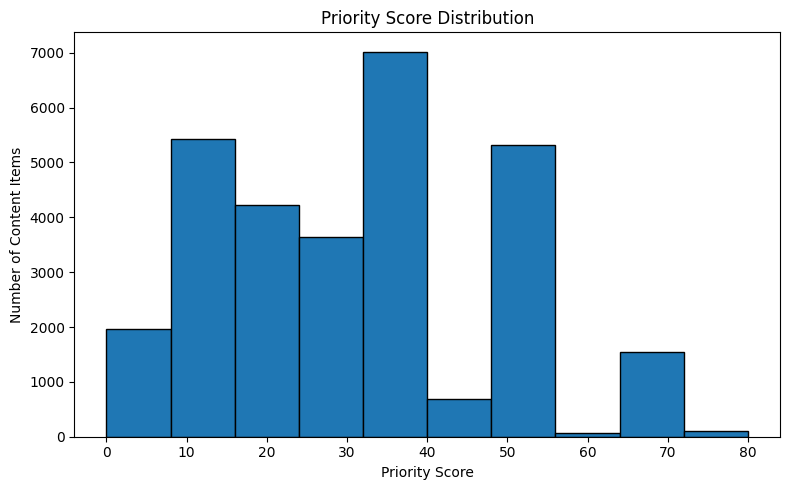

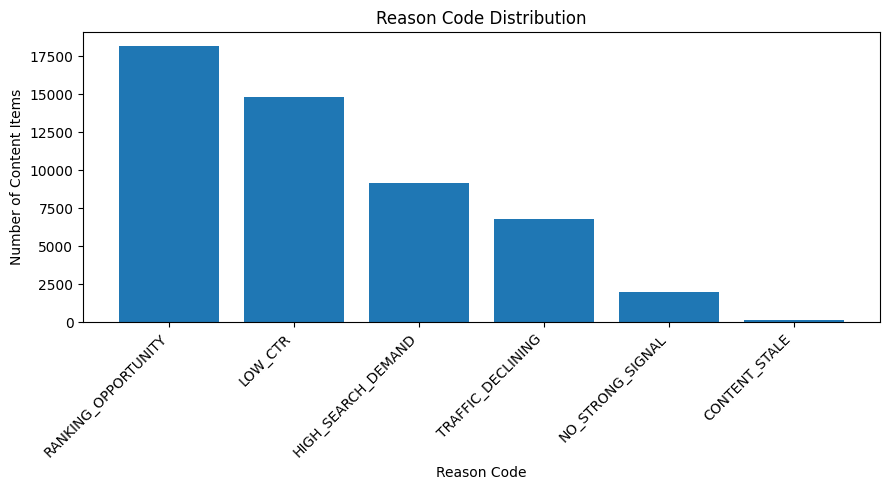

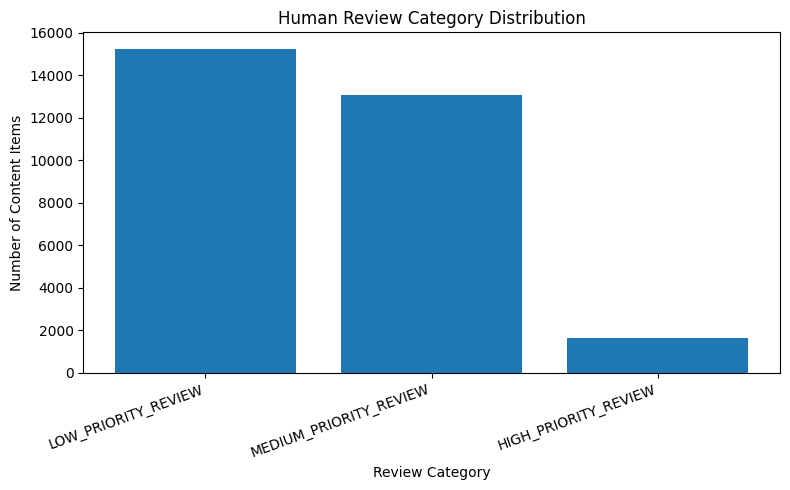


SECTION 5: EXPORTS FOR PAPER

OUTPUT FILES:
 - data_quality_summary.csv
 - human_review_summary.csv
 - paper_metrics.json
 - priority_score_summary.csv
 - ranked_action_queue.csv
 - reason_code_summary.csv

FIGURE FILES:
 - human_review_distribution.png
 - priority_score_distribution.png
 - reason_code_distribution.png

Section 5 completed successfully!
Outputs folder: /content/work/outputs
Figures folder: /content/work/figures


In [21]:
# ============================================================
# ML-10 | Section 5: Exports for Paper
# ============================================================

import os
import json
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Create Output Folders
# ------------------------------------------------------------

BASE_PATH = "/content/work"

OUTPUT_DIR = os.path.join(BASE_PATH, "outputs")
FIGURE_DIR = os.path.join(BASE_PATH, "figures")

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(FIGURE_DIR, exist_ok=True)

print("Output folders created successfully!")

# ------------------------------------------------------------
# 2. Export Ranked Action Queue
# ------------------------------------------------------------

# Remove client identifiers from the export
paper_queue = action_queue.copy()

paper_queue.to_csv(
    os.path.join(OUTPUT_DIR, "ranked_action_queue.csv"),
    index=False
)

print("Ranked action queue exported.")

# ------------------------------------------------------------
# 3. Export Priority Score Summary
# ------------------------------------------------------------

priority_summary = (
    action_queue["priority_score"]
    .describe()
    .round(2)
)

priority_summary.to_csv(
    os.path.join(OUTPUT_DIR, "priority_score_summary.csv")
)

# ------------------------------------------------------------
# 4. Export Reason Code Summary
# ------------------------------------------------------------

reason_summary = (
    action_queue["reason_codes"]
    .str.split(", ")
    .explode()
    .value_counts()
    .rename_axis("reason_code")
    .reset_index(name="count")
)

reason_summary.to_csv(
    os.path.join(OUTPUT_DIR, "reason_code_summary.csv"),
    index=False
)

# ------------------------------------------------------------
# 5. Export Human Review Summary
# ------------------------------------------------------------

review_summary = (
    review_queue["review_category"]
    .value_counts()
    .rename_axis("review_category")
    .reset_index(name="count")
)

review_summary.to_csv(
    os.path.join(OUTPUT_DIR, "human_review_summary.csv"),
    index=False
)

# ------------------------------------------------------------
# 6. Export Data Quality Summary
# ------------------------------------------------------------

missing_export = pd.DataFrame({
    "column": df.columns,
    "missing_count": df.isnull().sum().values,
    "missing_percentage": (
        df.isnull().mean().values * 100
    ).round(2)
})

missing_export = missing_export.sort_values(
    "missing_percentage",
    ascending=False
)

missing_export.to_csv(
    os.path.join(OUTPUT_DIR, "data_quality_summary.csv"),
    index=False
)

# ------------------------------------------------------------
# 7. Create Paper Figures
# ------------------------------------------------------------

# Figure 1: Priority Score Distribution

plt.figure(figsize=(8, 5))

plt.hist(
    action_queue["priority_score"],
    bins=10,
    edgecolor="black"
)

plt.title("Priority Score Distribution")
plt.xlabel("Priority Score")
plt.ylabel("Number of Content Items")
plt.tight_layout()

plt.savefig(
    os.path.join(FIGURE_DIR, "priority_score_distribution.png"),
    dpi=300
)

plt.show()
plt.close()

# Figure 2: Reason Code Distribution

plt.figure(figsize=(9, 5))

plt.bar(
    reason_summary["reason_code"],
    reason_summary["count"]
)

plt.title("Reason Code Distribution")
plt.xlabel("Reason Code")
plt.ylabel("Number of Content Items")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig(
    os.path.join(FIGURE_DIR, "reason_code_distribution.png"),
    dpi=300
)

plt.show()
plt.close()

# Figure 3: Human Review Categories

plt.figure(figsize=(8, 5))

plt.bar(
    review_summary["review_category"],
    review_summary["count"]
)

plt.title("Human Review Category Distribution")
plt.xlabel("Review Category")
plt.ylabel("Number of Content Items")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()

plt.savefig(
    os.path.join(FIGURE_DIR, "human_review_distribution.png"),
    dpi=300
)

plt.show()
plt.close()

# ------------------------------------------------------------
# 8. Create Combined Metrics JSON
# ------------------------------------------------------------

paper_metrics = {
    "dataset": {
        "rows": int(df.shape[0]),
        "columns": int(df.shape[1])
    },

    "priority_scores": {
        "mean": round(float(action_queue["priority_score"].mean()), 2),
        "median": round(float(action_queue["priority_score"].median()), 2),
        "minimum": int(action_queue["priority_score"].min()),
        "maximum": int(action_queue["priority_score"].max())
    },

    "high_priority_items": int(
        (action_queue["priority_score"] >= 65).sum()
    ),

    "traffic_declining_items": int(
        (df["clicks_last_30d"] < df["clicks_prev_30d"]).sum()
    ),

    "below_median_ctr_items": int(
        (df["ctr"] < df["ctr"].median()).sum()
    ),

    "missing_values": {
        "total": int(df.isnull().sum().sum()),
        "overall_percentage": round(
            float(df.isnull().sum().sum() / df.size * 100), 2
        )
    },

    "human_review": {
        "pending_items": int(
            (review_queue["review_status"] == "PENDING").sum()
        ),
        "high_priority": int(
            (review_queue["review_category"] == "HIGH_PRIORITY_REVIEW").sum()
        ),
        "medium_priority": int(
            (review_queue["review_category"] == "MEDIUM_PRIORITY_REVIEW").sum()
        ),
        "low_priority": int(
            (review_queue["review_category"] == "LOW_PRIORITY_REVIEW").sum()
        )
    },

    "scoring_method": "Rule-based heuristic",
    "validation_status": "Not a validated predictive model"
}

with open(
    os.path.join(OUTPUT_DIR, "paper_metrics.json"),
    "w"
) as file:
    json.dump(paper_metrics, file, indent=4)

# ------------------------------------------------------------
# 9. Display Exported Files
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("SECTION 5: EXPORTS FOR PAPER")
print("=" * 60)

print("\nOUTPUT FILES:")

for filename in sorted(os.listdir(OUTPUT_DIR)):
    print(" -", filename)

print("\nFIGURE FILES:")

for filename in sorted(os.listdir(FIGURE_DIR)):
    print(" -", filename)

print("\nSection 5 completed successfully!")
print("Outputs folder:", OUTPUT_DIR)
print("Figures folder:", FIGURE_DIR)

## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.